# 1. 불러오기와 기본 점검 ✅
최종 표를 불러와 연도·분기 칸을 나누고, 0값·음수·이상한 비율을 점검함
- 21,572행 · 154칸 확인, 음수 없음
- 아파트_가구_수: 원본에서 전부 0 (방배아이파크아파트 상권도 0) → 사용 안 함
- 학교·백화점·터미널 등 0이 많은 칸은 시설이 없는 상권이 대부분이라 정상
- 폐업률 100% 초과 1행 (분모가 분기 말 카페 수라서 생김) → 유지, 폐업률은 주의해서 사용
- 표가 2024년부터 시작함 → 그래프는 분기 순서로 정렬해서 그리기

In [1]:
# 도구 불러오기, 그래프 한글 폰트 설정
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"   # 그래프 한글 깨짐 방지
plt.rcParams["axes.unicode_minus"] = False      # 마이너스 기호 깨짐 방지

In [2]:
# 최종 표 불러오기 / 분기 코드를 연도와 분기로 나누기 (20214 다음이 20221이라 숫자 계산용으로 분리)
df = pd.read_csv("../data/processed/cafe_full_2021_2025.csv")
print(df.shape)
df["연도"] = df["기준_년분기_코드"] // 10
df["분기"] = df["기준_년분기_코드"] % 10
print(df[["기준_년분기_코드", "연도", "분기"]].drop_duplicates().head(6))

(21572, 154)
      기준_년분기_코드    연도  분기
0         20241  2024   1
1087      20242  2024   2
2171      20243  2024   3
3259      20244  2024   4
4348      20251  2025   1
5425      20252  2025   2


In [3]:
# 숫자 칸만 골라서 0값·음수 점검 / 개업률·폐업률 100% 초과 행 확인
num = df.select_dtypes("number")
zero = (num == 0).sum()
print("0이 하나라도 있는 칸:", (zero > 0).sum(), "개")
print(zero.sort_values(ascending=False).head(15))
print("음수 자리 수:", (num < 0).sum().sum())
print("폐업률 100 초과 행:", (df["폐업_률"] > 100).sum())
print("개업률 100 초과 행:", (df["개업_율"] > 100).sum())

0이 하나라도 있는 칸: 127 개
아파트_가구_수            21469
공항_수                21241
버스_터미널_수            21201
중학교_수               21161
고등학교_수              21044
백화점_수               21021
초등학교_수              21006
종합병원_수              20822
슈퍼마켓_수              20062
대학교_수               19770
극장_수                19664
숙박_시설_수             19065
일반_병원_수             18822
유치원_수               18751
남성연령대_10_직장_인구_수    18202
dtype: int64
음수 자리 수: 0
폐업률 100 초과 행: 1
개업률 100 초과 행: 0


# 2. 점포당 매출 만들기 ✅
점포당_매출 = 당월_매출_금액 ÷ 유사_업종_점포_수 (프랜차이즈 포함 카페 수)
- 분모 0 없음, 빈칸 없음
- 중앙값 1,320만 원, 평균 2,129만 원 → 큰 상권이 평균을 끌어올림 (그래서 비교 기준은 중앙값)
- 단위(월/분기)는 확인 중. 변화율로 비교하므로 분석 결과에는 영향 없음
- 최솟값 472원 = 면목역 2번 2024년 1분기 (카페 14곳, 매출 6,604원·13건) → 추정 실패
- 점포당 매출 100만 원 미만 1,059행(4.9%) → 변화율 계산 때 두 해 모두 100만 원 이상인 행만 사용

In [4]:
# 점포당 매출 = 분기 매출 ÷ 카페 수 (카페 수는 프랜차이즈 포함인 유사_업종_점포_수)
df["점포당_매출"] = df["당월_매출_금액"] / df["유사_업종_점포_수"]
print("분모가 0인 행:", (df["유사_업종_점포_수"] == 0).sum())
print("빈칸:", df["점포당_매출"].isna().sum())
print(df["점포당_매출"].describe().round(0))

분모가 0인 행: 0
빈칸: 0
count        21572.0
mean      21293221.0
std       26034661.0
min            472.0
25%        5487453.0
50%       13202538.0
75%       27781846.0
max      359955677.0
Name: 점포당_매출, dtype: float64


# 3. 예측 대상 만들기 (전년 같은 분기 대비) ✅
상권마다 올해 점포당 매출을 전년 같은 분기와 비교하고, 같은 분기의 중앙값보다 높으면 1(잘버팀)로 표시함
- 전년 같은 분기와 짝이 있는 행 16,745 (2021년은 비교 대상이 없어 제외)
- 조건: 두 해 모두 카페 5곳 이상 + 점포당 분기 매출 100만 원 이상 → 13,413행 (상권 950곳)
- 연도별: 2022년 3,262 / 2023년 3,360 / 2024년 3,413 / 2025년 3,378
- 잘버팀 1: 6,702 / 0: 6,711 (중앙값 기준이라 반반)
- 중앙값은 서울 전체가 아니라 조건을 통과한 상권 중의 중앙값
- 연도별 변화율 중앙값: 2022년 +0.8% → 2023년 −0.7% → 2024년 −0.8% → 2025년 −1.7% (물가 반영 전)
  → 자리 잡은 상권의 보통 상권도 점포당 매출이 해마다 줄고 있음
- 한계: 카페 5곳 미만으로 줄어든 상권(375행), 새로 5곳 이상이 된 상권(523행)은 빠짐
- 결과: 13,413행 → processed/cafe_target_2022_2025.csv

In [5]:
# 전년 같은 분기 값을 옆에 붙이기: 작년 값의 연도를 +1 해서, 올해 행과 (상권, 연도, 분기)로 짝 맞춤
prev = df[["상권_코드", "연도", "분기", "점포당_매출", "유사_업종_점포_수"]].copy()
prev["연도"] = prev["연도"] + 1
prev = prev.rename(columns={"점포당_매출": "전년_점포당_매출", "유사_업종_점포_수": "전년_카페수"})
pair = pd.merge(df, prev, on=["상권_코드", "연도", "분기"], how="inner")
print(pair.shape)
print(pair["연도"].value_counts().sort_index())

(16745, 159)
연도
2022    4118
2023    4195
2024    4222
2025    4210
Name: count, dtype: int64


In [6]:
# 조건: 두 해 모두 카페 5곳 이상 + 점포당 분기 매출 100만 원 이상 (작은 상권 출렁임, 추정 실패 행 제외)
cond = ((pair["유사_업종_점포_수"] >= 5) & (pair["전년_카페수"] >= 5) &
        (pair["점포당_매출"] >= 1_000_000) & (pair["전년_점포당_매출"] >= 1_000_000))
data = pair[cond].copy()
print(data.shape)
print(data["연도"].value_counts().sort_index())

(13413, 159)
연도
2022    3262
2023    3360
2024    3413
2025    3378
Name: count, dtype: int64


In [7]:
# 점포당 매출 변화율 = (올해 - 작년) ÷ 작년
data["변화율"] = (data["점포당_매출"] - data["전년_점포당_매출"]) / data["전년_점포당_매출"]

# 같은 분기(연도+분기) 안에서 서울 중앙값을 구해 행마다 붙이기
data["서울_중앙값"] = data.groupby(["연도", "분기"])["변화율"].transform("median")

# 서울 중앙값보다 높으면 1(잘 버팀), 아니면 0
data["잘버팀"] = (data["변화율"] > data["서울_중앙값"]).astype(int)

print(data["잘버팀"].value_counts())
print(data.groupby("연도")["변화율"].median().round(3))

잘버팀
0    6711
1    6702
Name: count, dtype: int64
연도
2022    0.008
2023   -0.007
2024   -0.008
2025   -0.017
Name: 변화율, dtype: float64


In [8]:
# 예측 대상까지 붙은 표 저장 (모델링용)
data.to_csv("../data/processed/cafe_target_2022_2025.csv", index=False, encoding="utf-8-sig")
print(data.shape)

(13413, 162)


# 4. 분기별·연도별 서울 흐름 ✅
분기별·연도별로 서울 전체 카페 수, 매출 합계, 점포당 매출이 어떻게 변했는지 봄 (매출이 있는 상권 기준)
- 분기 그래프는 계절 차이(1분기 낮고 2~3분기 높음)가 커서 연도별로 다시 그림
- 2021→2025: 카페 수 +11% (2024년 정점 후 감소), 매출 합계 +19% (2023년 이후 정체), 카페 한 곳 1년 매출 +7% (물가 반영 전)
- 2025년 한 곳 매출 증가는 매출보다 카페 수가 더 많이 줄어서 생김 → 약한 가게가 빠진 효과 가능성
- 같은 상권 기준 변화율 중앙값은 해마다 마이너스 → 서울 전체 숫자와 보통 상권의 흐름이 다름 (큰 상권과 폐업 효과)
- 그림: reports/figures/01_분기별_흐름.png, 02_연도별_흐름.png

In [9]:
# 분기별로 묶어서 카페 수 합계, 매출 합계, 점포당 매출 중앙값 구하기 (분기 순서로 정렬)
trend = df.groupby("기준_년분기_코드").agg(
    카페수=("유사_업종_점포_수", "sum"),
    매출합계=("당월_매출_금액", "sum"),
    점포당_중앙값=("점포당_매출", "median"),
).sort_index()
trend["매출합계_억"] = trend["매출합계"] / 1e8
trend["점포당_중앙값_만"] = trend["점포당_중앙값"] / 1e4
print(trend[["카페수", "매출합계_억", "점포당_중앙값_만"]].round(0))

             카페수  매출합계_억  점포당_중앙값_만
기준_년분기_코드                          
20211      18482  4763.0     1113.0
20212      18893  6112.0     1420.0
20213      19251  5900.0     1369.0
20214      19870  6400.0     1305.0
20221      20156  5485.0     1173.0
20222      20798  7043.0     1490.0
20223      20975  7099.0     1411.0
20224      21642  6929.0     1270.0
20231      21661  6758.0     1240.0
20232      21998  7186.0     1411.0
20233      21955  7127.0     1361.0
20234      22017  6880.0     1267.0
20241      22150  6615.0     1219.0
20242      22072  7374.0     1421.0
20243      21926  7186.0     1380.0
20244      21728  6913.0     1306.0
20251      21438  6325.0     1197.0
20252      21335  7046.0     1361.0
20253      21170  7347.0     1404.0
20254      20997  6864.0     1334.0


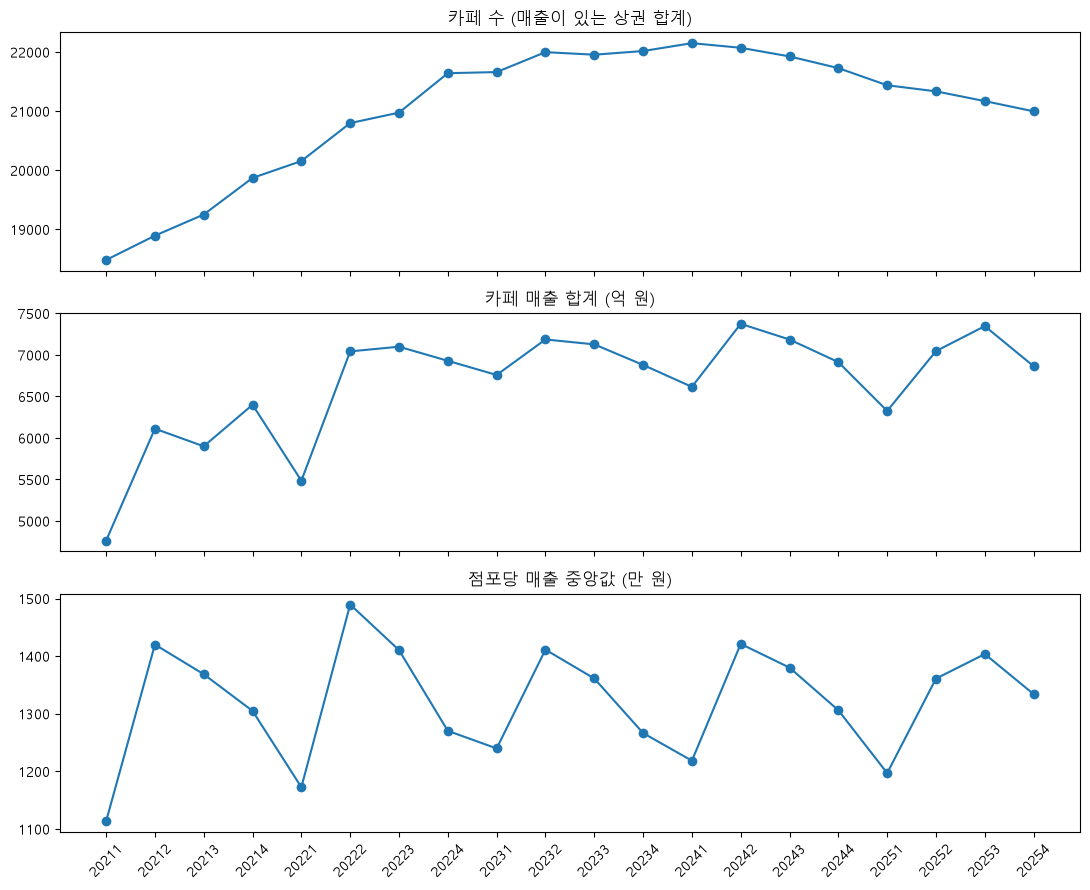

In [10]:
# 세 지표를 위아래로 그래프 3개 그리기 (x축은 분기)
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
x = trend.index.astype(str)
axes[0].plot(x, trend["카페수"], marker="o")
axes[0].set_title("카페 수 (매출이 있는 상권 합계)")
axes[1].plot(x, trend["매출합계_억"], marker="o")
axes[1].set_title("카페 매출 합계 (억 원)")
axes[2].plot(x, trend["점포당_중앙값_만"], marker="o")
axes[2].set_title("점포당 매출 중앙값 (만 원)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../reports/figures/01_분기별_흐름.png", dpi=150)
plt.show()

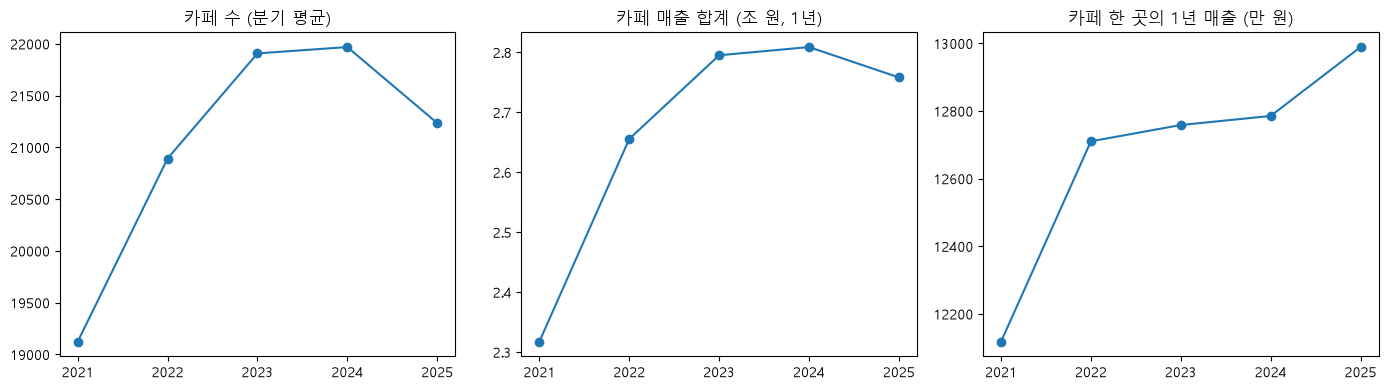

           카페수  매출합계_조  점포당_매출_만
연도                              
2021  19124.00    2.32  12118.05
2022  20892.75    2.66  12710.42
2023  21907.75    2.80  12758.63
2024  21969.00    2.81  12785.45
2025  21235.00    2.76  12989.15


In [11]:
# 연도별로 묶어서 다시 그리기 (계절 톱니 없애기)
yearly = df.groupby("연도").agg(
    카페수=("유사_업종_점포_수", "sum"),          # ★ 4분기 합계라서 아래에서 4로 나눔
    매출합계=("당월_매출_금액", "sum"),
)
yearly["카페수"] = yearly["카페수"] / 4             # ★ 분기 평균 카페 수
yearly["매출합계_조"] = yearly["매출합계"] / 1e12    # 1조 단위
yearly["점포당_매출_만"] = yearly["매출합계"] / yearly["카페수"] / 1e4   # ★ 카페 한 곳의 1년 매출

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(yearly.index, yearly["카페수"], marker="o"); axes[0].set_title("카페 수 (분기 평균)")
axes[1].plot(yearly.index, yearly["매출합계_조"], marker="o"); axes[1].set_title("카페 매출 합계 (조 원, 1년)")
axes[2].plot(yearly.index, yearly["점포당_매출_만"], marker="o"); axes[2].set_title("카페 한 곳의 1년 매출 (만 원)")
for ax in axes:
    ax.set_xticks(yearly.index)
plt.tight_layout()
plt.savefig("../reports/figures/02_연도별_흐름.png", dpi=150)
plt.show()
print(yearly[["카페수", "매출합계_조", "점포당_매출_만"]].round(2))

# 5. 변화율 분포 ✅
상권마다 전년 같은 분기 대비 점포당 매출 변화율이 얼마나 퍼져 있는지 봄 (13,413행)
- 중앙값 −0.7%, 평균 +7.7% → 크게 오른 일부 상권이 평균을 끌어올림
- 하위 10%는 −30% 이하, 상위 10%는 +44% 이상 → 같은 카페 상권이라도 결과가 크게 갈림
- 오른쪽 꼬리가 김 (최대 +1,746%): 감소는 −100%가 바닥이지만 증가는 끝이 없어서 생기는 모양
- 예측 대상은 중앙값 기준이라 극단값에 흔들리지 않음
- 그림: reports/figures/03_변화율_분포.png

In [12]:
# 변화율 요약: 하위 10%, 25%, 중앙값, 75%, 상위 10% 지점 (★ 퍼진 정도를 숫자로 확인)
print(data["변화율"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3))

count    13413.000
mean         0.077
std          0.581
min         -0.914
10%         -0.302
25%         -0.152
50%         -0.007
75%          0.169
90%          0.440
max         17.456
Name: 변화율, dtype: float64


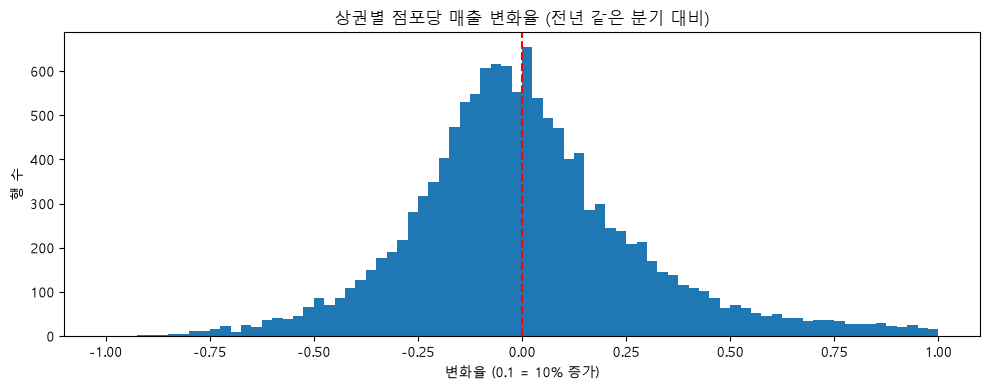

In [13]:
# 변화율 히스토그램 (★ -100%~+100% 구간만 그림, 0% 위치에 세로선)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(data["변화율"], bins=80, range=(-1, 1))
ax.axvline(0, color="red", linestyle="--")
ax.set_title("상권별 점포당 매출 변화율 (전년 같은 분기 대비)")
ax.set_xlabel("변화율 (0.1 = 10% 증가)")
ax.set_ylabel("행 수")
plt.tight_layout()
plt.savefig("../reports/figures/03_변화율_분포.png", dpi=150)
plt.show()